# Fase 4 — Notebook 2: Análise de Vídeo Clínico

**Objetivo:** Processar vídeos de sessões de fisioterapia para detectar padrões posturais e eventos fora do padrão esperado.

**Pipeline:**
1. Download do vídeo (yt-dlp)
2. EDA — Exploração do vídeo (frames, FPS, duração)
3. Detecção de pose corporal (MediaPipe)
4. Detecção de objetos e pessoas (YOLOv8)
5. Análise de movimento e simetria postural
6. Detecção de padrões anômalos
7. Relatório clínico gerado por IA (Claude API)

## Célula 1 — Instalação de dependências

In [7]:
# Célula 1 — Instalação com versão do MediaPipe compatível com solutions API
!pip install yt-dlp "mediapipe==0.10.14" ultralytics opencv-python \
             python-dotenv anthropic matplotlib \
             pandas numpy --quiet

print("✅ Dependências instaladas!")


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
✅ Dependências instaladas!


## Célula 2 — Imports e configuração de ambiente

In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import cv2
import mediapipe as mp
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from ultralytics import YOLO
import anthropic
from dotenv import load_dotenv

warnings.filterwarnings('ignore')

load_dotenv()
ANTHROPIC_API_KEY = os.getenv("ANTHROPIC_API_KEY")
assert ANTHROPIC_API_KEY, "❌ ANTHROPIC_API_KEY não encontrada no .env!"

Path("data/video").mkdir(parents=True, exist_ok=True)
Path("data/frames").mkdir(parents=True, exist_ok=True)

print("✅ Imports e ambiente configurados!")
print(f"   OpenCV   : {cv2.__version__}")
print(f"   MediaPipe: {mp.__version__}")

✅ Imports e ambiente configurados!
   OpenCV   : 5.1.0
   MediaPipe: 0.10.14


## Célula 3 — Download do vídeo com yt-dlp

In [2]:
URL_VIDEO = "https://www.youtube.com/watch?v=kPaLYolpN7w"
CAMINHO_VIDEO = Path("data/video/fisioterapia.mp4")

if not CAMINHO_VIDEO.exists():
    print("⬇️  Baixando vídeo...")
    !yt-dlp -f "bestvideo[ext=mp4][height<=480]+bestaudio[ext=m4a]/best[ext=mp4][height<=480]" \
        --merge-output-format mp4 \
        -o "{CAMINHO_VIDEO}" \
        "{URL_VIDEO}"
    print("✅ Download concluído!")
else:
    print("✅ Vídeo já baixado — usando cache local.")

print(f"   Arquivo : {CAMINHO_VIDEO}")
print(f"   Tamanho : {CAMINHO_VIDEO.stat().st_size / 1024 / 1024:.1f} MB")

✅ Vídeo já baixado — usando cache local.
   Arquivo : data/video/fisioterapia.mp4
   Tamanho : 22.6 MB


## Célula 4 — EDA: Propriedades do vídeo

📹 Propriedades do vídeo:
   Resolução    : 854 x 480 px
   FPS          : 25.0
   Total frames : 11,675
   Duração      : 467.0s (7.8 min)


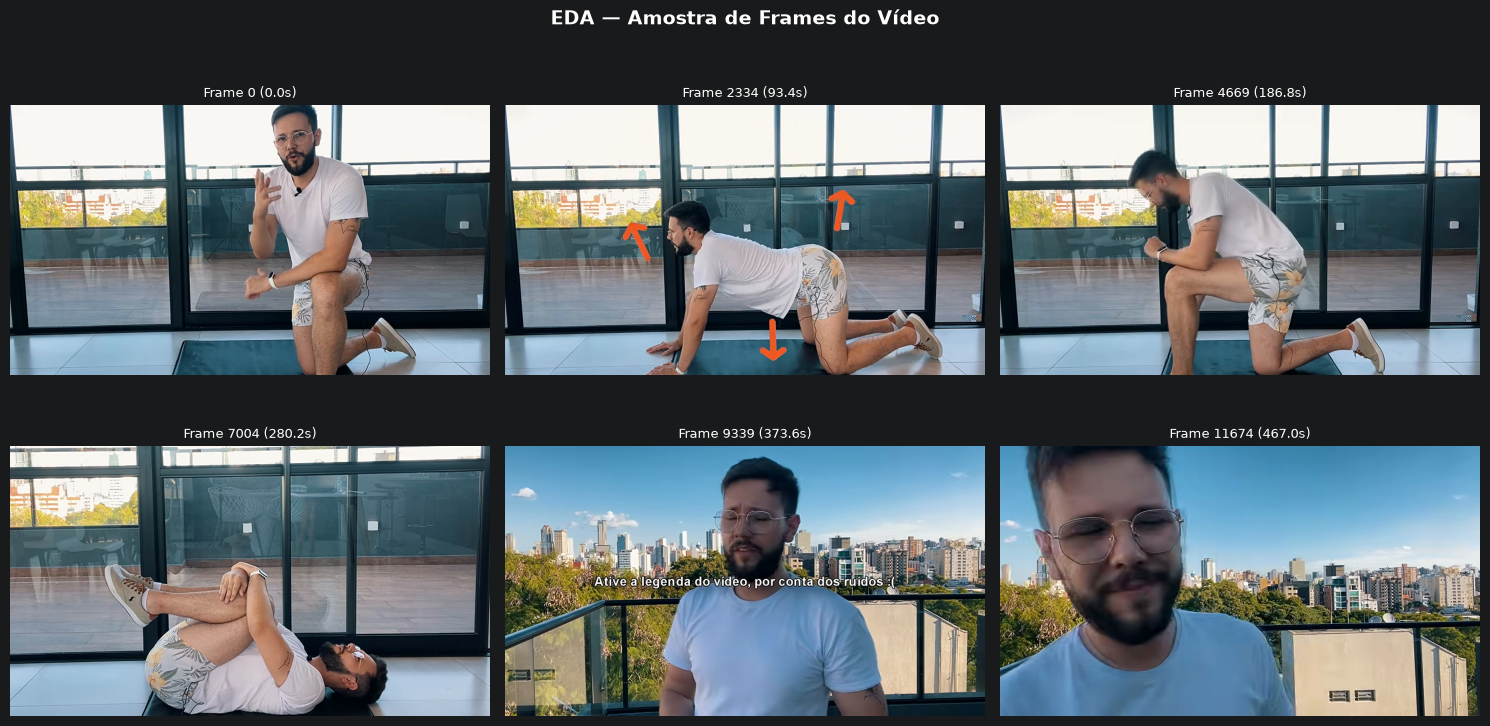

✅ Frames salvos em data/04_frames_amostra.png


In [3]:
cap = cv2.VideoCapture(str(CAMINHO_VIDEO))

fps         = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
largura     = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
altura      = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duracao_s   = total_frames / fps

print("📹 Propriedades do vídeo:")
print(f"   Resolução    : {largura} x {altura} px")
print(f"   FPS          : {fps:.1f}")
print(f"   Total frames : {total_frames:,}")
print(f"   Duração      : {duracao_s:.1f}s ({duracao_s/60:.1f} min)")

# Extrai e exibe 6 frames em momentos distribuídos no vídeo
indices_amostra = np.linspace(0, total_frames - 1, 6, dtype=int)
frames_amostra  = []

for idx in indices_amostra:
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ret, frame = cap.read()
    if ret:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames_amostra.append((idx, frame_rgb))

cap.release()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('EDA — Amostra de Frames do Vídeo', fontsize=14, fontweight='bold')

for ax, (idx, frame) in zip(axes.flat, frames_amostra):
    ax.imshow(frame)
    ax.set_title(f'Frame {idx} ({idx/fps:.1f}s)', fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig('data/04_frames_amostra.png', dpi=120, bbox_inches='tight')
plt.show()
print("✅ Frames salvos em data/04_frames_amostra.png")

## Célula 5 — Detecção de pose com MediaPipe

O MediaPipe detecta **33 keypoints** do corpo humano em cada frame.
Usamos esses pontos para calcular ângulos articulares e simetria postural.

In [4]:
mp_pose    = mp.solutions.pose
mp_drawing = mp.solutions.drawing_utils
mp_drawing_styles = mp.solutions.drawing_styles

# Índices dos keypoints relevantes para análise clínica
KEYPOINTS = {
    'ombro_esq' : mp_pose.PoseLandmark.LEFT_SHOULDER,
    'ombro_dir' : mp_pose.PoseLandmark.RIGHT_SHOULDER,
    'quadril_esq': mp_pose.PoseLandmark.LEFT_HIP,
    'quadril_dir': mp_pose.PoseLandmark.RIGHT_HIP,
    'joelho_esq' : mp_pose.PoseLandmark.LEFT_KNEE,
    'joelho_dir' : mp_pose.PoseLandmark.RIGHT_KNEE,
    'tornozelo_esq': mp_pose.PoseLandmark.LEFT_ANKLE,
    'tornozelo_dir': mp_pose.PoseLandmark.RIGHT_ANKLE,
    'cotovelo_esq' : mp_pose.PoseLandmark.LEFT_ELBOW,
    'cotovelo_dir' : mp_pose.PoseLandmark.RIGHT_ELBOW,
    'punho_esq'    : mp_pose.PoseLandmark.LEFT_WRIST,
    'punho_dir'    : mp_pose.PoseLandmark.RIGHT_WRIST,
}

def calcular_angulo(p1, p2, p3):
    """
    Calcula o ângulo (em graus) entre três pontos.
    p2 é o vértice do ângulo.
    """
    v1 = np.array([p1.x - p2.x, p1.y - p2.y])
    v2 = np.array([p3.x - p2.x, p3.y - p2.y])
    cos_angulo = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-6)
    angulo = np.degrees(np.arccos(np.clip(cos_angulo, -1.0, 1.0)))
    return float(angulo)

def extrair_metricas_pose(landmarks):
    """Extrai métricas clínicas de postura a partir dos landmarks do MediaPipe."""
    lm = landmarks.landmark

    # Ângulo do joelho esquerdo (quadril → joelho → tornozelo)
    angulo_joelho_esq = calcular_angulo(
        lm[mp_pose.PoseLandmark.LEFT_HIP],
        lm[mp_pose.PoseLandmark.LEFT_KNEE],
        lm[mp_pose.PoseLandmark.LEFT_ANKLE]
    )

    # Ângulo do joelho direito
    angulo_joelho_dir = calcular_angulo(
        lm[mp_pose.PoseLandmark.RIGHT_HIP],
        lm[mp_pose.PoseLandmark.RIGHT_KNEE],
        lm[mp_pose.PoseLandmark.RIGHT_ANKLE]
    )

    # Ângulo do cotovelo esquerdo (ombro → cotovelo → punho)
    angulo_cotovelo_esq = calcular_angulo(
        lm[mp_pose.PoseLandmark.LEFT_SHOULDER],
        lm[mp_pose.PoseLandmark.LEFT_ELBOW],
        lm[mp_pose.PoseLandmark.LEFT_WRIST]
    )

    # Ângulo do cotovelo direito
    angulo_cotovelo_dir = calcular_angulo(
        lm[mp_pose.PoseLandmark.RIGHT_SHOULDER],
        lm[mp_pose.PoseLandmark.RIGHT_ELBOW],
        lm[mp_pose.PoseLandmark.RIGHT_WRIST]
    )

    # Alinhamento dos ombros (diferença de altura Y entre ombro esq e dir)
    desnivel_ombros = abs(
        lm[mp_pose.PoseLandmark.LEFT_SHOULDER].y -
        lm[mp_pose.PoseLandmark.RIGHT_SHOULDER].y
    )

    # Alinhamento do quadril
    desnivel_quadril = abs(
        lm[mp_pose.PoseLandmark.LEFT_HIP].y -
        lm[mp_pose.PoseLandmark.RIGHT_HIP].y
    )

    # Simetria dos joelhos (diferença de ângulo entre esq e dir)
    assimetria_joelhos = abs(angulo_joelho_esq - angulo_joelho_dir)

    # Visibilidade média dos pontos-chave
    visibilidades = [lm[kp].visibility for kp in KEYPOINTS.values()]
    visibilidade_media = float(np.mean(visibilidades))

    return {
        'angulo_joelho_esq'   : round(angulo_joelho_esq, 1),
        'angulo_joelho_dir'   : round(angulo_joelho_dir, 1),
        'angulo_cotovelo_esq' : round(angulo_cotovelo_esq, 1),
        'angulo_cotovelo_dir' : round(angulo_cotovelo_dir, 1),
        'desnivel_ombros'     : round(float(desnivel_ombros), 4),
        'desnivel_quadril'    : round(float(desnivel_quadril), 4),
        'assimetria_joelhos'  : round(assimetria_joelhos, 1),
        'visibilidade_media'  : round(visibilidade_media, 3)
    }

print("✅ MediaPipe Pose configurado!")
print(f"   Keypoints disponíveis: {len(mp_pose.PoseLandmark)}")

✅ MediaPipe Pose configurado!
   Keypoints disponíveis: 33


## Célula 6 — Processa frames com MediaPipe (amostragem)

In [5]:
# Processa 1 frame a cada N frames para eficiência
INTERVALO_FRAMES = 15  # ~0.5s em 30fps

cap = cv2.VideoCapture(str(CAMINHO_VIDEO))
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

registros_pose  = []
frames_anotados = []   # Frames com skeleton desenhado (para visualização)
frame_idx       = 0
processados     = 0

print(f"🔄 Processando vídeo ({total_frames} frames, 1 a cada {INTERVALO_FRAMES})...")

with mp_pose.Pose(
    static_image_mode=False,
    model_complexity=1,
    smooth_landmarks=True,
    min_detection_confidence=0.5,
    min_tracking_confidence=0.5
) as pose:

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break

        if frame_idx % INTERVALO_FRAMES == 0:
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            resultado = pose.process(frame_rgb)

            tempo_s = frame_idx / fps

            if resultado.pose_landmarks:
                metricas = extrair_metricas_pose(resultado.pose_landmarks)
                metricas['frame']   = frame_idx
                metricas['tempo_s'] = round(tempo_s, 2)
                metricas['pose_detectada'] = True
                registros_pose.append(metricas)

                # Desenha skeleton no frame para visualização
                frame_anotado = frame_rgb.copy()
                mp_drawing.draw_landmarks(
                    frame_anotado,
                    resultado.pose_landmarks,
                    mp_pose.POSE_CONNECTIONS,
                    landmark_drawing_spec=mp_drawing_styles.get_default_pose_landmarks_style()
                )
                frames_anotados.append((frame_idx, tempo_s, frame_anotado))
            else:
                registros_pose.append({
                    'frame': frame_idx, 'tempo_s': round(tempo_s, 2),
                    'pose_detectada': False
                })

            processados += 1

        frame_idx += 1

cap.release()

df_pose = pd.DataFrame([r for r in registros_pose if r.get('pose_detectada')])

print(f"\n✅ Processamento concluído!")
print(f"   Frames analisados    : {processados}")
print(f"   Poses detectadas     : {len(df_pose)}")
print(f"   Taxa de detecção     : {len(df_pose)/processados*100:.1f}%")
print(f"   Duração coberta      : {df_pose['tempo_s'].max():.1f}s")

🔄 Processando vídeo (11675 frames, 1 a cada 15)...


I0000 00:00:1794948844.078835   24756 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1794948844.082944   24886 gl_context.cc:357] GL version: 3.2 (OpenGL ES 3.2 Mesa 25.2.8-0ubuntu0.24.04.2), renderer: AMD Radeon RX 7600 (radeonsi, navi33, LLVM 20.1.2, DRM 3.64, 7.0.0-38-generic)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1794948844.142150   24864 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1794948844.159988   24867 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.



✅ Processamento concluído!
   Frames analisados    : 779
   Poses detectadas     : 762
   Taxa de detecção     : 97.8%
   Duração coberta      : 466.8s


## Célula 7 — Visualização: skeleton e evolução temporal dos ângulos

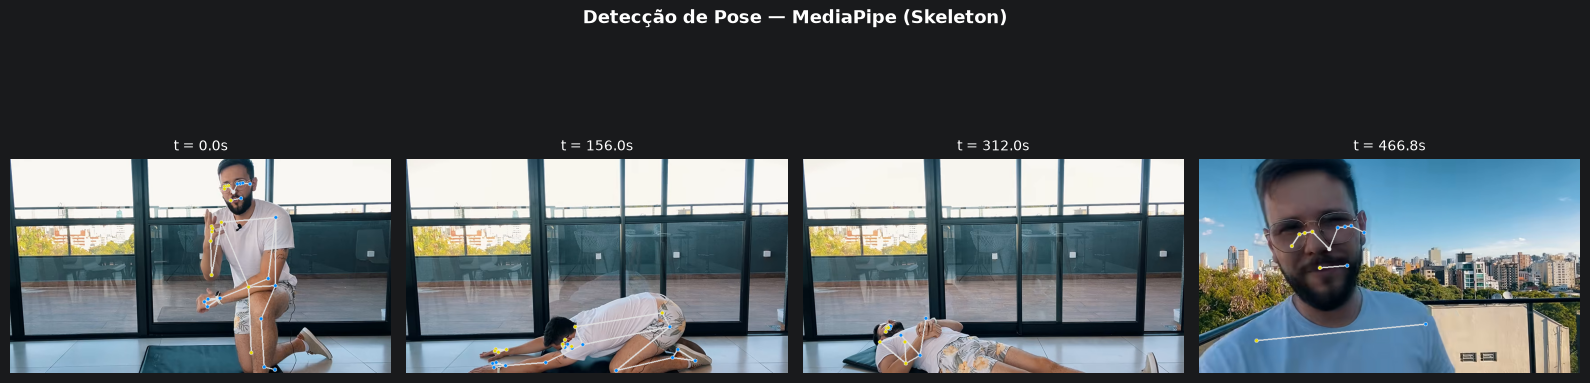

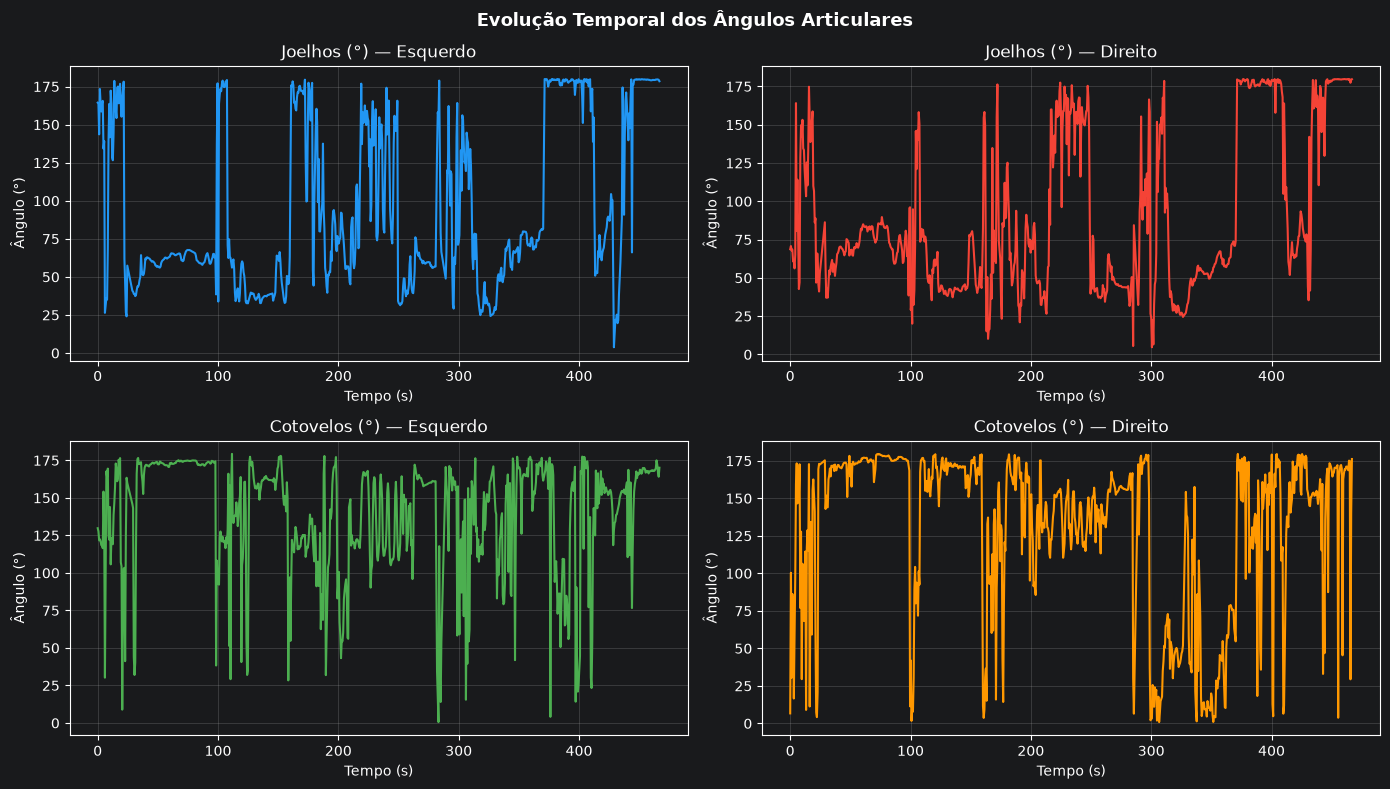

✅ Gráficos salvos!


In [6]:
# --- Parte 1: Exibe frames com skeleton em 4 momentos do vídeo ---
n_exibir = min(4, len(frames_anotados))
indices_exibir = np.linspace(0, len(frames_anotados)-1, n_exibir, dtype=int)

fig, axes = plt.subplots(1, n_exibir, figsize=(16, 5))
fig.suptitle('Detecção de Pose — MediaPipe (Skeleton)', fontsize=13, fontweight='bold')

for ax, idx in zip(axes, indices_exibir):
    frame_num, tempo, frame_ann = frames_anotados[idx]
    ax.imshow(frame_ann)
    ax.set_title(f't = {tempo:.1f}s', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig('data/05_pose_skeleton.png', dpi=120, bbox_inches='tight')
plt.show()

# --- Parte 2: Evolução temporal dos ângulos articulares ---
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Evolução Temporal dos Ângulos Articulares', fontsize=13, fontweight='bold')

metricas_plot = [
    ('angulo_joelho_esq',  'angulo_joelho_dir',  'Joelhos (°)',    '#2196F3', '#F44336'),
    ('angulo_cotovelo_esq','angulo_cotovelo_dir', 'Cotovelos (°)', '#4CAF50', '#FF9800'),
]

for i, (col_esq, col_dir, titulo, cor_esq, cor_dir) in enumerate(metricas_plot):
    ax_esq = axes[i, 0]
    ax_dir = axes[i, 1]

    ax_esq.plot(df_pose['tempo_s'], df_pose[col_esq], color=cor_esq, linewidth=1.5)
    ax_esq.set_title(f'{titulo} — Esquerdo')
    ax_esq.set_xlabel('Tempo (s)')
    ax_esq.set_ylabel('Ângulo (°)')
    ax_esq.grid(True, alpha=0.3)

    ax_dir.plot(df_pose['tempo_s'], df_pose[col_dir], color=cor_dir, linewidth=1.5)
    ax_dir.set_title(f'{titulo} — Direito')
    ax_dir.set_xlabel('Tempo (s)')
    ax_dir.set_ylabel('Ângulo (°)')
    ax_dir.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('data/06_angulos_temporais.png', dpi=120, bbox_inches='tight')
plt.show()
print("✅ Gráficos salvos!")

## Célula 8 — Detecção de objetos com YOLOv8

In [7]:
print("⬇️  Carregando modelo YOLOv8n (nano)...")
modelo_yolo = YOLO("yolov8n.pt")  # Baixa automaticamente na primeira execução
print("✅ YOLOv8 carregado!")

# Categorias relevantes para contexto clínico/fisioterapia
CLASSES_RELEVANTES = {
    0 : 'pessoa',
    56: 'cadeira',
    57: 'sofa',
    58: 'vaso',
    60: 'mesa',
    73: 'laptop',
    74: 'mouse',
}

# Processa frames amostrados com YOLO
cap = cv2.VideoCapture(str(CAMINHO_VIDEO))
fps = cap.get(cv2.CAP_PROP_FPS)

registros_yolo  = []
frames_yolo     = []
frame_idx       = 0
INTERVALO_YOLO  = 30  # 1 frame por segundo aprox.

print(f"\n🔄 Rodando YOLOv8 no vídeo (1 frame a cada {INTERVALO_YOLO})...")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    if frame_idx % INTERVALO_YOLO == 0:
        tempo_s   = frame_idx / fps
        resultado = modelo_yolo(frame, verbose=False)[0]

        deteccoes = []
        for box in resultado.boxes:
            cls_id     = int(box.cls[0])
            confianca  = float(box.conf[0])
            nome_classe = resultado.names[cls_id]
            coords     = box.xyxy[0].tolist()

            if confianca >= 0.4:
                deteccoes.append({
                    'classe'   : nome_classe,
                    'confianca': round(confianca, 3),
                    'bbox'     : [round(c, 1) for c in coords]
                })

        registros_yolo.append({
            'frame'      : frame_idx,
            'tempo_s'    : round(tempo_s, 2),
            'n_pessoas'  : sum(1 for d in deteccoes if d['classe'] == 'person'),
            'n_objetos'  : len(deteccoes),
            'deteccoes'  : deteccoes
        })

        # Salva frames com detecções visíveis
        if len(deteccoes) > 0:
            frame_ann = resultado.plot()
            frame_rgb = cv2.cvtColor(frame_ann, cv2.COLOR_BGR2RGB)
            frames_yolo.append((frame_idx, tempo_s, frame_rgb))

    frame_idx += 1

cap.release()

df_yolo = pd.DataFrame(registros_yolo)
print(f"\n✅ YOLOv8 concluído!")
print(f"   Frames analisados : {len(df_yolo)}")
print(f"   Frames com pessoas: {(df_yolo['n_pessoas'] > 0).sum()}")
print(f"   Média de pessoas/frame: {df_yolo['n_pessoas'].mean():.2f}")

⬇️  Carregando modelo YOLOv8n (nano)...
✅ YOLOv8 carregado!

🔄 Rodando YOLOv8 no vídeo (1 frame a cada 30)...

✅ YOLOv8 concluído!
   Frames analisados : 390
   Frames com pessoas: 382
   Média de pessoas/frame: 1.02


## Célula 9 — Visualização: detecções YOLOv8

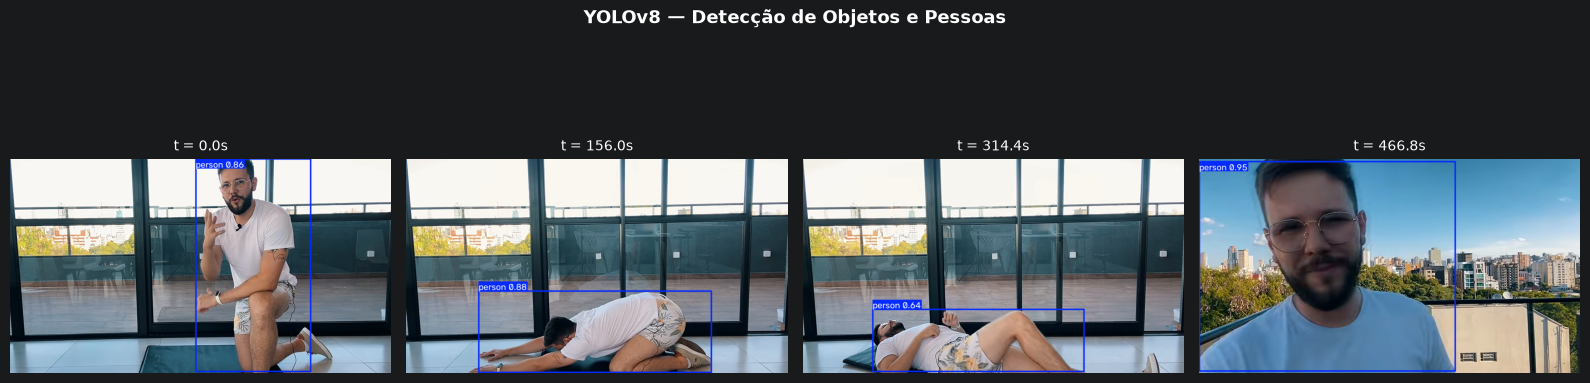

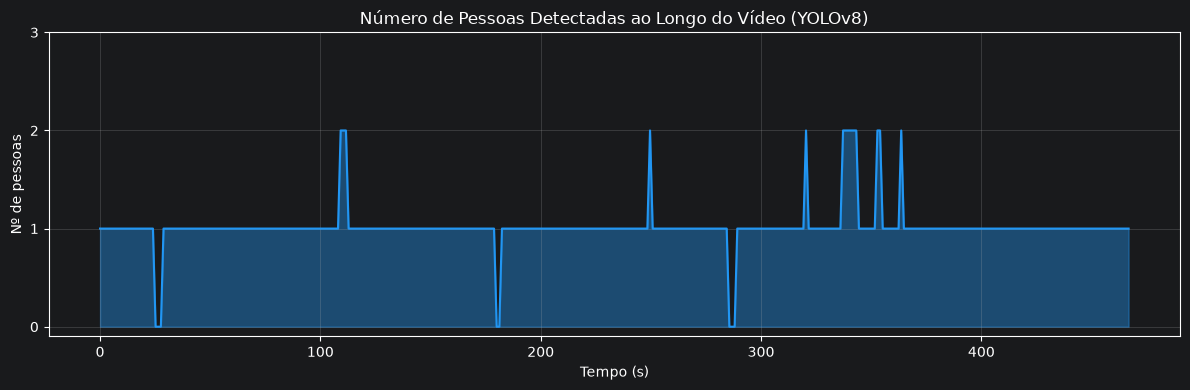

✅ Visualizações YOLOv8 salvas!


In [8]:
# Exibe frames com bounding boxes do YOLO
n_exibir = min(4, len(frames_yolo))

if n_exibir > 0:
    indices = np.linspace(0, len(frames_yolo)-1, n_exibir, dtype=int)
    fig, axes = plt.subplots(1, n_exibir, figsize=(16, 5))
    fig.suptitle('YOLOv8 — Detecção de Objetos e Pessoas', fontsize=13, fontweight='bold')

    for ax, idx in zip(axes if n_exibir > 1 else [axes], indices):
        f_num, f_tempo, f_rgb = frames_yolo[idx]
        ax.imshow(f_rgb)
        ax.set_title(f't = {f_tempo:.1f}s', fontsize=10)
        ax.axis('off')

    plt.tight_layout()
    plt.savefig('data/07_yolo_deteccoes.png', dpi=120, bbox_inches='tight')
    plt.show()

# Gráfico: nº de pessoas ao longo do tempo
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(df_yolo['tempo_s'], df_yolo['n_pessoas'], alpha=0.4, color='#2196F3')
ax.plot(df_yolo['tempo_s'], df_yolo['n_pessoas'], color='#2196F3', linewidth=1.5)
ax.set_title('Número de Pessoas Detectadas ao Longo do Vídeo (YOLOv8)')
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('Nº de pessoas')
ax.set_yticks(range(int(df_yolo['n_pessoas'].max()) + 2))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('data/08_pessoas_tempo.png', dpi=120, bbox_inches='tight')
plt.show()
print("✅ Visualizações YOLOv8 salvas!")

## Célula 10 — Detecção de padrões anômalos no movimento

Detectamos anomalias posturais baseadas em limiares clínicos:
- **Assimetria de joelhos > 20°** → compensação postural
- **Desnível de ombros > 0.05** → escoliose ou desequilíbrio
- **Desnível de quadril > 0.05** → inclinação pélvica

🔍 Análise de Anomalias Posturais:
   Total de frames analisados : 762
   Frames com alerta (≥2 flags): 241 (31.6%)

   ⚠️  Assimetria de joelhos > 20°: 202 frames (26.5%)
   ⚠️  Desnível de ombros > 5%: 341 frames (44.8%)
   ⚠️  Desnível de quadril > 5%: 233 frames (30.6%)


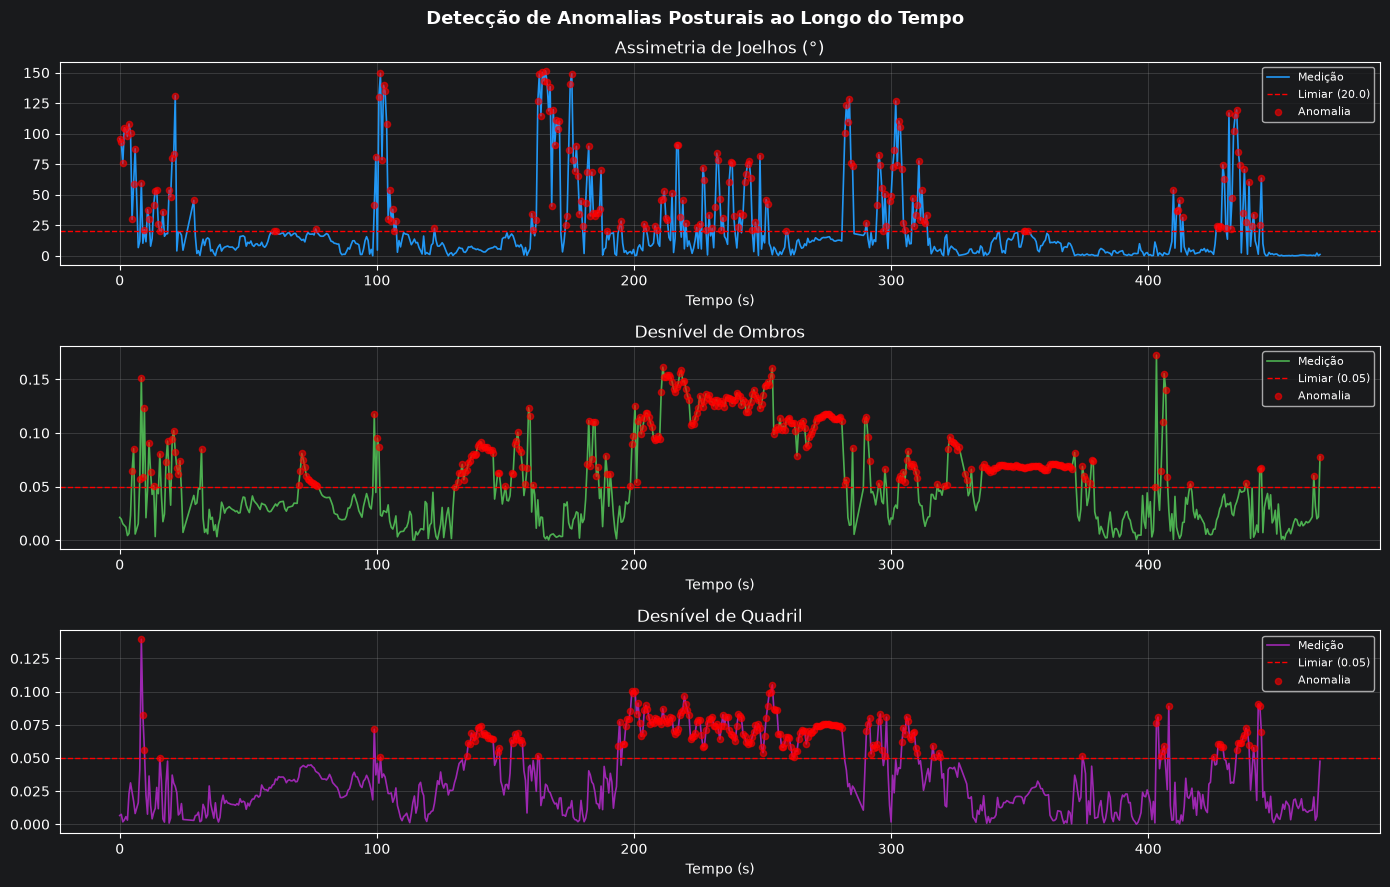


✅ Gráfico salvo em data/09_anomalias_posturais.png


In [11]:
# Limiares clínicos para detecção de anomalias
LIMIARES = {
    'assimetria_joelhos' : {'limiar': 20.0,  'descricao': 'Assimetria de joelhos > 20°'},
    'desnivel_ombros'    : {'limiar': 0.05,  'descricao': 'Desnível de ombros > 5%'},
    'desnivel_quadril'   : {'limiar': 0.05,  'descricao': 'Desnível de quadril > 5%'},
}

def detectar_anomalias_postural(df):
    """Aplica limiares clínicos e retorna DataFrame com flags de anomalia."""
    df = df.copy()

    df['anomalia_joelho']  = df['assimetria_joelhos'] > LIMIARES['assimetria_joelhos']['limiar']
    df['anomalia_ombro']   = df['desnivel_ombros']    > LIMIARES['desnivel_ombros']['limiar']
    df['anomalia_quadril'] = df['desnivel_quadril']   > LIMIARES['desnivel_quadril']['limiar']
    df['n_anomalias']      = df[['anomalia_joelho', 'anomalia_ombro', 'anomalia_quadril']].sum(axis=1)
    df['alerta']           = df['n_anomalias'] >= 2

    return df

df_pose = detectar_anomalias_postural(df_pose)

# Resumo
total = len(df_pose)
alertas = df_pose['alerta'].sum()

print("🔍 Análise de Anomalias Posturais:")
print("=" * 50)
print(f"   Total de frames analisados : {total}")
print(f"   Frames com alerta (≥2 flags): {alertas} ({alertas/total*100:.1f}%)")
print()

# Mapeamento direto — evita derivar nome da coluna via split
resumo_anomalias = {
    'Assimetria de joelhos > 20°': 'anomalia_joelho',
    'Desnível de ombros > 5%'    : 'anomalia_ombro',
    'Desnível de quadril > 5%'   : 'anomalia_quadril',
}
for descricao, col_flag in resumo_anomalias.items():
    n = df_pose[col_flag].sum()
    print(f"   ⚠️  {descricao}: {n} frames ({n/total*100:.1f}%)")

# Visualiza anomalias ao longo do tempo
fig, axes = plt.subplots(3, 1, figsize=(14, 9))
fig.suptitle('Detecção de Anomalias Posturais ao Longo do Tempo', fontsize=13, fontweight='bold')

configs = [
    ('assimetria_joelhos', 'anomalia_joelho',  LIMIARES['assimetria_joelhos']['limiar'],
     'Assimetria de Joelhos (°)', '#2196F3'),
    ('desnivel_ombros',    'anomalia_ombro',   LIMIARES['desnivel_ombros']['limiar'],
     'Desnível de Ombros', '#4CAF50'),
    ('desnivel_quadril',   'anomalia_quadril', LIMIARES['desnivel_quadril']['limiar'],
     'Desnível de Quadril', '#9C27B0'),
]

for ax, (col_val, col_flag, limiar, titulo, cor) in zip(axes, configs):
    ax.plot(df_pose['tempo_s'], df_pose[col_val], color=cor, linewidth=1.2, label='Medição')
    ax.axhline(y=limiar, color='red', linestyle='--', linewidth=1, label=f'Limiar ({limiar})')

    # Destaca frames com anomalia
    anomalos = df_pose[df_pose[col_flag]]
    ax.scatter(anomalos['tempo_s'], anomalos[col_val],
               color='red', s=20, zorder=5, label='Anomalia', alpha=0.6)

    ax.set_title(titulo)
    ax.set_xlabel('Tempo (s)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('data/09_anomalias_posturais.png', dpi=120, bbox_inches='tight')
plt.show()
print("\n✅ Gráfico salvo em data/09_anomalias_posturais.png")

## Célula 11 — Relatório clínico de vídeo gerado pela Claude API

In [12]:
import numpy as np

class EncoderJSON(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, (np.floating, np.float32, np.float64)): return float(obj)
        if isinstance(obj, (np.integer, np.int32, np.int64)):      return int(obj)
        if isinstance(obj, np.bool_):                               return bool(obj)
        if isinstance(obj, np.ndarray):                             return obj.tolist()
        return super().default(obj)

cliente = anthropic.Anthropic(api_key=ANTHROPIC_API_KEY)

def gerar_relatorio_video(df_pose, df_yolo, id_paciente="P001"):
    """Gera relatório clínico de análise de vídeo via Claude API."""

    total_frames = len(df_pose)
    n_alertas    = int(df_pose['alerta'].sum())
    pct_alertas  = round(n_alertas / total_frames * 100, 1) if total_frames > 0 else 0

    # Estatísticas dos ângulos
    stats_joelho_esq = df_pose['angulo_joelho_esq'].describe()
    stats_joelho_dir = df_pose['angulo_joelho_dir'].describe()
    media_assimetria = round(float(df_pose['assimetria_joelhos'].mean()), 1)
    max_assimetria   = round(float(df_pose['assimetria_joelhos'].max()), 1)
    media_desnivel_ombros  = round(float(df_pose['desnivel_ombros'].mean()), 4)
    media_desnivel_quadril = round(float(df_pose['desnivel_quadril'].mean()), 4)

    # Anomalias por tipo
    anomalia_joelho  = int(df_pose['anomalia_joelho'].sum())
    anomalia_ombro   = int(df_pose['anomalia_ombro'].sum())
    anomalia_quadril = int(df_pose['anomalia_quadril'].sum())

    prompt = f"""Você é um fisioterapeuta especialista em análise biomecânica.
Analise os dados abaixo de uma sessão de fisioterapia gravada em vídeo e gere um relatório clínico em PORTUGUÊS DO BRASIL.

=== DADOS DO PACIENTE {id_paciente} ===

DURAÇÃO DA SESSÃO ANALISADA: {round(float(df_pose['tempo_s'].max()), 1)} segundos
FRAMES COM POSE DETECTADA: {total_frames}

ÂNGULOS ARTICULARES:
- Joelho Esquerdo: média {round(float(stats_joelho_esq['mean']), 1)}° (mín {round(float(stats_joelho_esq['min']), 1)}°, máx {round(float(stats_joelho_esq['max']), 1)}°)
- Joelho Direito:  média {round(float(stats_joelho_dir['mean']), 1)}° (mín {round(float(stats_joelho_dir['min']), 1)}°, máx {round(float(stats_joelho_dir['max']), 1)}°)
- Assimetria média entre joelhos: {media_assimetria}° (máx: {max_assimetria}°)

ALINHAMENTO POSTURAL:
- Desnível médio de ombros: {media_desnivel_ombros:.4f} (limiar: 0.05)
- Desnível médio de quadril: {media_desnivel_quadril:.4f} (limiar: 0.05)

ANOMALIAS DETECTADAS:
- Frames com alerta (≥2 flags): {n_alertas}/{total_frames} ({pct_alertas}%)
- Assimetria de joelhos > 20°: {anomalia_joelho} frames
- Desnível de ombros > 5%: {anomalia_ombro} frames
- Desnível de quadril > 5%: {anomalia_quadril} frames

DETECÇÃO DE PESSOAS (YOLOv8):
- Média de pessoas no frame: {round(float(df_yolo['n_pessoas'].mean()), 2)}

Gere um relatório clínico com:
1. Resumo geral da sessão
2. Achados biomecânicos (ângulos, simetria, postura)
3. Anomalias identificadas e sua relevância clínica
4. Nível de risco: Baixo / Médio / Alto
5. Recomendações para o fisioterapeuta

Use linguagem técnica mas acessível."""

    resposta = cliente.messages.create(
        model="claude-opus-4-5",
        max_tokens=1024,
        messages=[{"role": "user", "content": prompt}]
    )

    return resposta.content[0].text

print("🤖 Gerando relatório clínico com Claude API...")
relatorio_video = gerar_relatorio_video(df_pose, df_yolo, id_paciente="P001")

print("\n" + "="*60)
print("RELATÓRIO CLÍNICO — ANÁLISE DE VÍDEO")
print("="*60)
print(relatorio_video)

# Salva JSON
resultado_video = {
    'id_paciente'     : 'P001',
    'duracao_s'       : float(df_pose['tempo_s'].max()),
    'frames_analisados': len(df_pose),
    'taxa_alerta_pct' : round(float(df_pose['alerta'].sum()) / len(df_pose) * 100, 1),
    'media_assimetria_joelhos': float(df_pose['assimetria_joelhos'].mean()),
    'media_desnivel_ombros'   : float(df_pose['desnivel_ombros'].mean()),
    'relatorio_clinico': relatorio_video
}

with open('data/relatorio_video_p001.json', 'w', encoding='utf-8') as f:
    json.dump(resultado_video, f, ensure_ascii=False, indent=2, cls=EncoderJSON)

print("\n✅ Relatório salvo em data/relatorio_video_p001.json")

🤖 Gerando relatório clínico com Claude API...

RELATÓRIO CLÍNICO — ANÁLISE DE VÍDEO
# RELATÓRIO DE ANÁLISE BIOMECÂNICA

---

**Paciente:** P001  
**Data da Análise:** Sessão de vídeo  
**Duração Total:** 7 minutos e 47 segundos (466,8s)  
**Frames Analisados:** 762 frames com pose detectada  

---

## 1. RESUMO GERAL DA SESSÃO

A sessão de fisioterapia foi analisada por meio de captura de movimento com detecção de pose em tempo real. O paciente foi identificado de forma consistente ao longo de toda a gravação (média de 1,02 pessoas por frame), indicando boa qualidade de rastreamento sem interferências significativas.

**Visão Geral dos Achados:**
O paciente apresenta **padrões biomecânicos que requerem atenção clínica**, com destaque para assimetrias funcionais entre membros inferiores e alterações no alinhamento postural da cintura escapular. Aproximadamente **1/3 da sessão (31,6%)** apresentou alertas simultâneos de múltiplos parâmetros.

---

## 2. ACHADOS BIOMECÂNICOS

### 2.1 Ângu

## Célula 12 — Dashboard final de análise de vídeo

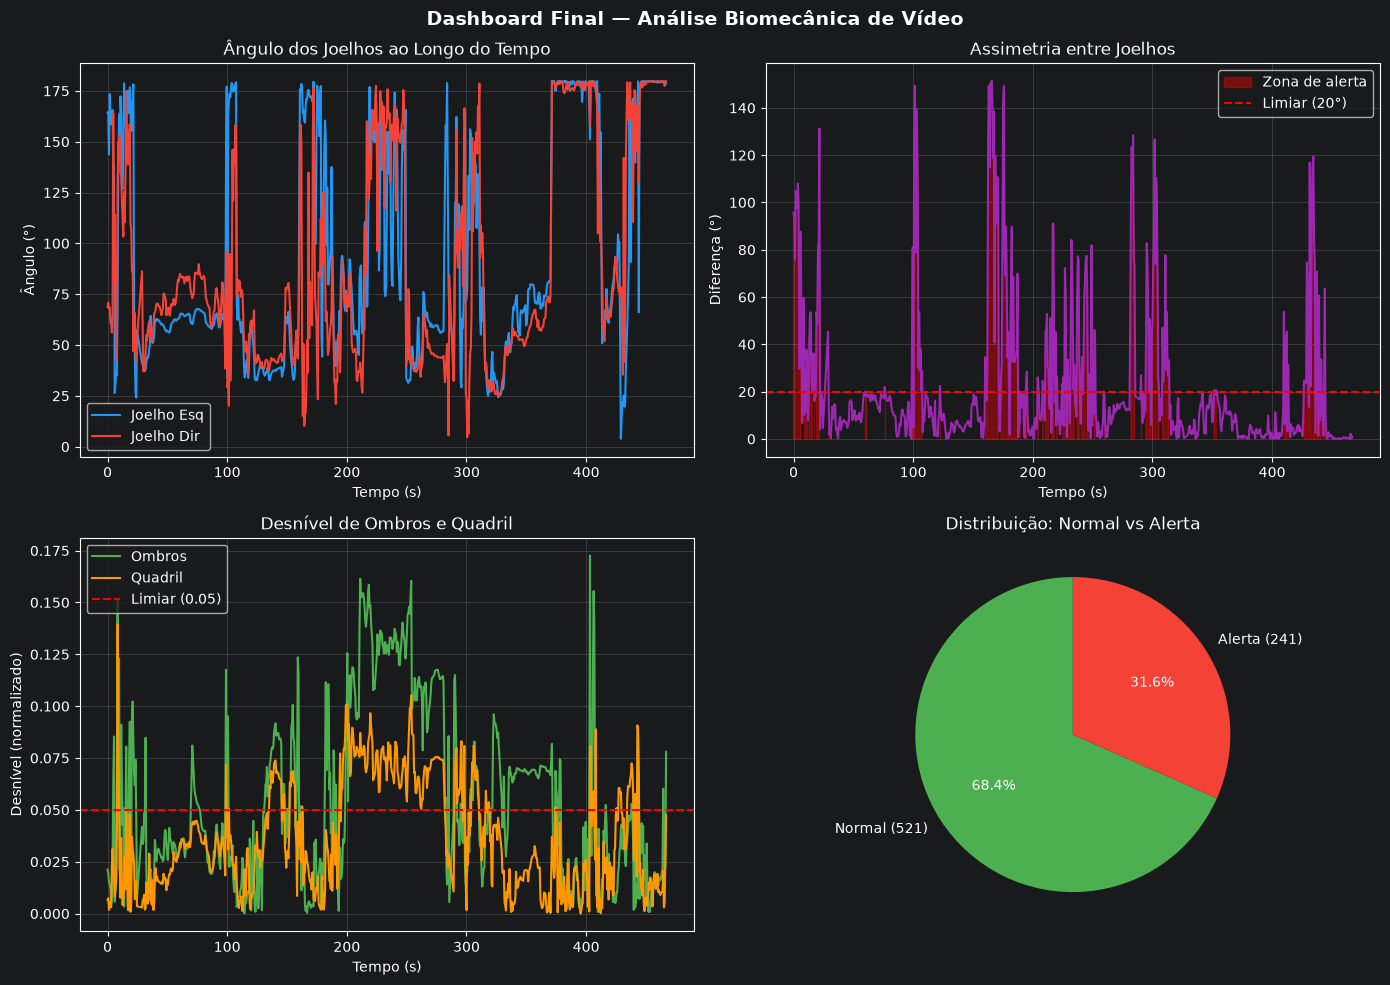


✅ Dashboard salvo em data/10_dashboard_video.png

RESUMO FINAL — ANÁLISE DE VÍDEO
   Frames com pose detectada : 762
   Frames com alerta         : 241 (31.6%)
   Assimetria média joelhos  : 21.7°
   Desnível médio ombros     : 0.0550

🔴 RISCO GERAL DA SESSÃO: Alto


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Dashboard Final — Análise Biomecânica de Vídeo', fontsize=14, fontweight='bold')

# 1. Comparação ângulo joelho esq vs dir ao longo do tempo
axes[0,0].plot(df_pose['tempo_s'], df_pose['angulo_joelho_esq'],
               label='Joelho Esq', color='#2196F3', linewidth=1.5)
axes[0,0].plot(df_pose['tempo_s'], df_pose['angulo_joelho_dir'],
               label='Joelho Dir', color='#F44336', linewidth=1.5)
axes[0,0].set_title('Ângulo dos Joelhos ao Longo do Tempo')
axes[0,0].set_xlabel('Tempo (s)')
axes[0,0].set_ylabel('Ângulo (°)')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# 2. Assimetria dos joelhos com área de alerta
axes[0,1].fill_between(df_pose['tempo_s'], df_pose['assimetria_joelhos'],
                        where=df_pose['anomalia_joelho'],
                        alpha=0.4, color='red', label='Zona de alerta')
axes[0,1].plot(df_pose['tempo_s'], df_pose['assimetria_joelhos'],
               color='#9C27B0', linewidth=1.5)
axes[0,1].axhline(y=20, color='red', linestyle='--', label='Limiar (20°)')
axes[0,1].set_title('Assimetria entre Joelhos')
axes[0,1].set_xlabel('Tempo (s)')
axes[0,1].set_ylabel('Diferença (°)')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# 3. Desnível de ombros e quadril
axes[1,0].plot(df_pose['tempo_s'], df_pose['desnivel_ombros'],
               label='Ombros', color='#4CAF50', linewidth=1.5)
axes[1,0].plot(df_pose['tempo_s'], df_pose['desnivel_quadril'],
               label='Quadril', color='#FF9800', linewidth=1.5)
axes[1,0].axhline(y=0.05, color='red', linestyle='--', label='Limiar (0.05)')
axes[1,0].set_title('Desnível de Ombros e Quadril')
axes[1,0].set_xlabel('Tempo (s)')
axes[1,0].set_ylabel('Desnível (normalizado)')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# 4. Pizza: distribuição de frames normais vs alerta
n_alerta  = int(df_pose['alerta'].sum())
n_normal  = len(df_pose) - n_alerta
axes[1,1].pie(
    [n_normal, n_alerta],
    labels=[f'Normal ({n_normal})', f'Alerta ({n_alerta})'],
    colors=['#4CAF50', '#F44336'],
    autopct='%1.1f%%',
    startangle=90
)
axes[1,1].set_title('Distribuição: Normal vs Alerta')

plt.tight_layout()
plt.savefig('data/10_dashboard_video.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Dashboard salvo em data/10_dashboard_video.png")
print("\n" + "="*60)
print("RESUMO FINAL — ANÁLISE DE VÍDEO")
print("="*60)
print(f"   Frames com pose detectada : {len(df_pose)}")
print(f"   Frames com alerta         : {n_alerta} ({n_alerta/len(df_pose)*100:.1f}%)")
print(f"   Assimetria média joelhos  : {df_pose['assimetria_joelhos'].mean():.1f}°")
print(f"   Desnível médio ombros     : {df_pose['desnivel_ombros'].mean():.4f}")
risco_final = 'Alto' if n_alerta/len(df_pose) > 0.3 else ('Médio' if n_alerta/len(df_pose) > 0.1 else 'Baixo')
emoji = {'Baixo': '🟢', 'Médio': '🟡', 'Alto': '🔴'}[risco_final]
print(f"\n{emoji} RISCO GERAL DA SESSÃO: {risco_final}")